<div style="font-family:Times New Roman;font-size:14pt;color:black"><b>Лабораторна робота 4 частина 2</b><br>Задача класифікації<br>Виконав Шиндир Олексій<br>4 курс, 10 група</div>

<a href="https://colab.research.google.com/github/raysewww-lang/mashynne-navchannia/blob/main/%D0%A8%D0%B8%D0%BD%D0%B4%D0%B8%D1%80_%D0%BF%D1%80_4_%D1%87%D0%B0%D1%81%D1%82%D0%B8%D0%BD%D0%B0_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Відкрити в Colab"/></a>

In [1]:
# Підготовка бібліотек і даних. Дані автоматично завантажуються з GitHub; резервний спосіб — data.zip.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
np.random.seed(25)
plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','DejaVu Serif'],'font.size':14,'figure.figsize':(9,5)})
pd.set_option('display.max_columns',40)

def data_path(name):
    for folder in [Path('data'),Path('.'),Path('/content/data'),Path('/content')]:
        p=folder/name
        if p.exists():
            return p
    import zipfile, io
    from urllib.request import urlopen
    try:
        url='https://raw.githubusercontent.com/raysewww-lang/mashynne-navchannia/main/data.zip'
        with urlopen(url, timeout=60) as response:
            content=response.read()
        Path('data').mkdir(exist_ok=True)
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            for member in z.namelist():
                if not member.endswith('/'):
                    (Path('data')/Path(member).name).write_bytes(z.read(member))
        if (Path('data')/name).exists():
            return Path('data')/name
    except Exception as error:
        print('Автоматичне завантаження недоступне:',error)
    from google.colab import files
    import zipfile, io
    print('Завантажте data.zip або файл',name)
    uploaded=files.upload()
    Path('data').mkdir(exist_ok=True)
    for fname,content in uploaded.items():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(io.BytesIO(content)) as z:
                for member in z.namelist():
                    if not member.endswith('/'):
                        (Path('data')/Path(member).name).write_bytes(z.read(member))
        else:
            (Path('data')/Path(fname).name).write_bytes(content)
    p=Path('data')/name
    if not p.exists():
        raise FileNotFoundError(name)
    return p

In [2]:
# Завдання 1. Завантаження Breast Cancer, перші рядки, типи, пропуски та розмір.
from sklearn.datasets import load_breast_cancer
dataset=load_breast_cancer(as_frame=True)
df=dataset.frame.copy()

display(df.head()); print('Розмір:',df.shape);display(df.dtypes)
display(df.isna().sum());print('Дублікати:',df.duplicated().sum())
df=df.drop_duplicates().copy()
display(df.describe())

print('Правильне кодування sklearn:',dict(enumerate(dataset.target_names)))
# У тексті методички класи переплутано. У sklearn 0 — malignant, 1 — benign.

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Розмір: (569, 31)


mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64
worst symmetry      

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

Дублікати: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


Правильне кодування sklearn: {0: np.str_('malignant'), 1: np.str_('benign')}


Логістична               precision    recall  f1-score   support

           0       1.00      0.95      0.98        42
           1       0.97      1.00      0.99        72

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



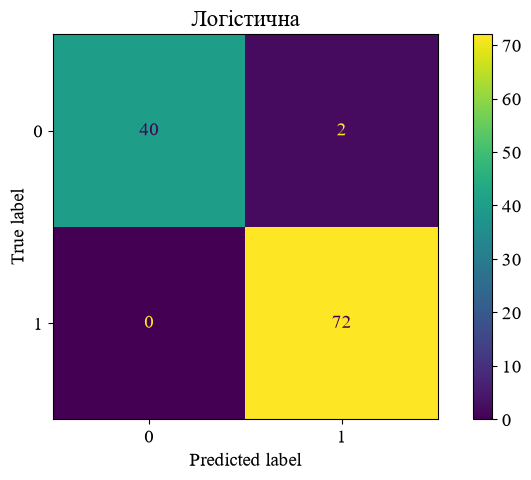

Дерево               precision    recall  f1-score   support

           0       0.88      0.90      0.89        42
           1       0.94      0.93      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



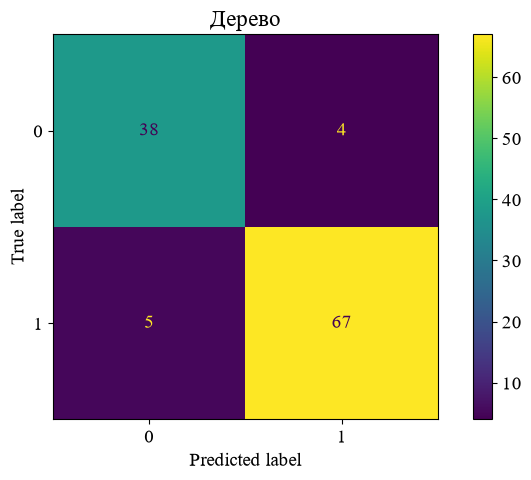

Ліс               precision    recall  f1-score   support

           0       0.95      0.95      0.95        42
           1       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



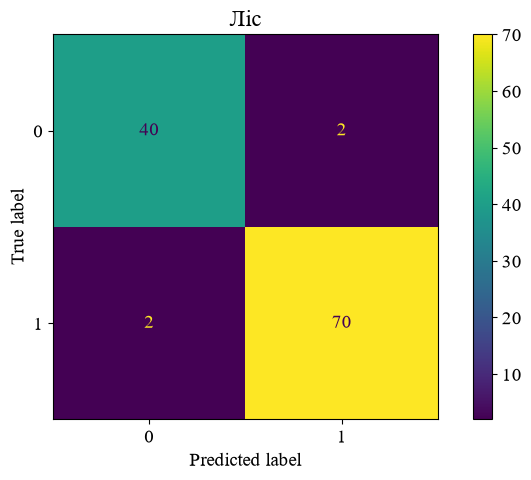

,Модель,CV accuracy,Test accuracy,Параметри
0,Логістична,0.978027,0.982456,{'model__C': 1}
1,Дерево,0.931858,0.921053,"{'model__max_depth': 5, 'model__min_samples_le..."
2,Ліс,0.956053,0.964912,"{'model__max_depth': None, 'model__min_samples..."


Найкраща за CV: Логістична


,Справжні,Прогноз
180,0,0
40,0,1
178,1,1
290,1,1
465,1,1
227,1,1
342,1,1
263,0,1
546,1,1
475,1,1


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Справжні,Прогноз
435,13.980,19.62,91.12,599.5,0.10600,0.11330,0.11260,0.06463,0.1669,0.06544,0.2208,0.9533,1.602,18.85,0.005314,0.01791,0.021850,0.009567,0.01223,0.002846,17.04,30.80,113.90,869.3,0.1613,0.3568,0.40690,0.18270,0.3179,0.10550,0,0
374,13.690,16.07,87.84,579.1,0.08302,0.06374,0.02556,0.02031,0.1872,0.05669,0.1705,0.5066,1.372,14.00,0.004230,0.01587,0.011690,0.006335,0.01943,0.002177,14.84,20.21,99.16,670.6,0.1105,0.2096,0.13460,0.06987,0.3323,0.07701,1,1
421,14.690,13.98,98.22,656.1,0.10310,0.18360,0.14500,0.06300,0.2086,0.07406,0.5462,1.5110,4.795,49.45,0.009976,0.05244,0.052780,0.015800,0.02653,0.005444,16.46,18.34,114.10,809.2,0.1312,0.3635,0.32190,0.11080,0.2827,0.09208,1,1
238,14.220,27.85,92.55,623.9,0.08223,0.10390,0.11030,0.04408,0.1342,0.06129,0.3354,2.3240,2.105,29.96,0.006307,0.02845,0.038500,0.010110,0.01185,0.003589,15.75,40.54,102.50,764.0,0.1081,0.2426,0.30640,0.08219,0.1890,0.07796,1,1
391,8.734,16.84,55.27,234.3,0.10390,0.07428,0.00000,0.00000,0.1985,0.07098,0.5169,2.0790,3.167,28.85,0.015820,0.01966,0.000000,0.000000,0.01865,0.006736,10.17,22.80,64.01,317.0,0.1460,0.1310,0.00000,0.00000,0.2445,0.08865,1,1
342,11.060,14.96,71.49,373.9,0.10330,0.09097,0.05397,0.03341,0.1776,0.06907,0.1601,0.8225,1.355,10.80,0.007416,0.01877,0.027580,0.010100,0.02348,0.002917,11.92,19.90,79.76,440.0,0.1418,0.2210,0.22990,0.10750,0.3301,0.09080,1,1
264,17.190,22.07,111.60,928.3,0.09726,0.08995,0.09061,0.06527,0.1867,0.05580,0.4203,0.7383,2.819,45.42,0.004493,0.01206,0.020480,0.009875,0.01144,0.001575,21.58,29.33,140.50,1436.0,0.1558,0.2567,0.38890,0.19840,0.3216,0.07570,0,0
124,13.370,16.39,86.10,553.5,0.07115,0.07325,0.08092,0.02800,0.1422,0.05823,0.1639,1.1400,1.223,14.66,0.005919,0.03270,0.049570,0.010380,0.01208,0.004076,14.26,22.75,91.99,632.1,0.1025,0.2531,0.33080,0.08978,0.2048,0.07628,1,1
514,15.050,19.07,97.26,701.9,0.09215,0.08597,0.07486,0.04335,0.1561,0.05915,0.3860,1.1980,2.630,38.49,0.004952,0.01630,0.029670,0.009423,0.01152,0.001718,17.58,28.06,113.80,967.0,0.1246,0.2101,0.28660,0.11200,0.2282,0.06954,0,0
436,12.870,19.54,82.67,509.2,0.09136,0.07883,0.01797,0.02090,0.1861,0.06347,0.3665,0.7693,2.597,26.50,0.005910,0.01362,0.007066,0.006502,0.02223,0.002378,14.45,24.38,95.14,626.9,0.1214,0.1652,0.07127,0.06384,0.3313,0.07735,1,1


In [3]:
# Завдання 1. Побудова, налаштування, оцінка, прогноз і висновок. Поділ, три класифікатори та GridSearchCV.
X=df.drop(columns='target');y=df.target
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=25,stratify=y)
numeric=X.select_dtypes(include='number').columns.tolist()
categorical=X.select_dtypes(exclude='number').columns.tolist()
pre=ColumnTransformer([
    ('num',Pipeline([('fill',SimpleImputer()),('scale',StandardScaler())]),numeric),
    ('cat',Pipeline([('fill',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore'))]),categorical)])
models={'Логістична':LogisticRegression(max_iter=3000),'Дерево':DecisionTreeClassifier(random_state=25),'Ліс':RandomForestClassifier(random_state=25,n_jobs=1)}
grids={'Логістична':{'model__C':[0.1,1,10]},'Дерево':{'model__max_depth':[3,5,None],'model__min_samples_leaf':[1,5]},'Ліс':{'model__n_estimators':[100],'model__max_depth':[5,None],'model__min_samples_leaf':[1,3]}}
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=25)
fitted={}; rows=[]
for name,model in models.items():
    grid=GridSearchCV(Pipeline([('pre',pre),('model',model)]),grids[name],cv=cv,scoring='accuracy',n_jobs=1)
    grid.fit(X_train,y_train);fitted[name]=grid
    pred=grid.predict(X_test)
    rows.append([name,grid.best_score_,accuracy_score(y_test,pred),grid.best_params_])
    print(name,classification_report(y_test,pred,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test,pred);plt.title(name);plt.show()
results=pd.DataFrame(rows,columns=['Модель','CV accuracy','Test accuracy','Параметри']);display(results)
best_name=results.loc[results['CV accuracy'].idxmax(),'Модель'];best=fitted[best_name]
print('Найкраща за CV:',best_name)
display(pd.DataFrame({'Справжні':y_test,'Прогноз':best.predict(X_test)}).head(20))
sample=X_test.sample(10,random_state=25)
display(sample.assign(Справжні=y_test.loc[sample.index],Прогноз=best.predict(sample)))

In [4]:
# Висновок. Завдання 1. Три класифікатори налаштовано за однаковою стратифікованою CV. Accuracy, звіти та матриці помилок наведено вище. Найкращу модель обрано за CV accuracy, а не за тестом. Значення 0 означає malignant, 1 — benign.

In [5]:
# Завдання 2. Завантаження Титаніка та попередній аналіз.
df=pd.read_csv(data_path('titanic (5).csv'))

display(df.head()); print('Розмір:',df.shape);display(df.dtypes)
display(df.isna().sum());print('Дублікати:',df.duplicated().sum())
df=df.drop_duplicates().copy()
display(df.describe())

df=df.drop(columns=['PassengerId','Name','Ticket','Cabin'])

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Розмір: (891, 12)


PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Дублікати: 0


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Логістична               precision    recall  f1-score   support

           0       0.81      0.86      0.84       110
           1       0.76      0.68      0.72        69

    accuracy                           0.79       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.79      0.79      0.79       179



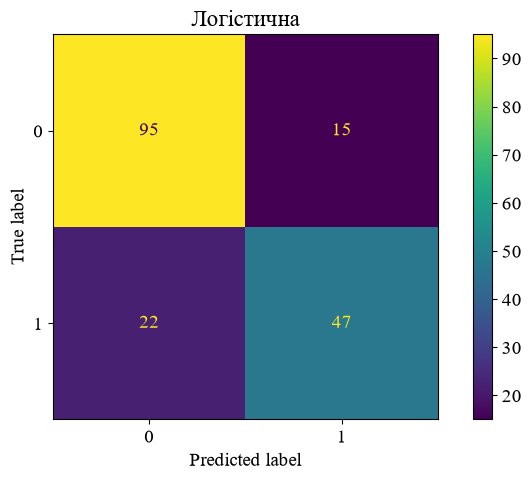

Дерево               precision    recall  f1-score   support

           0       0.83      0.88      0.85       110
           1       0.79      0.71      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



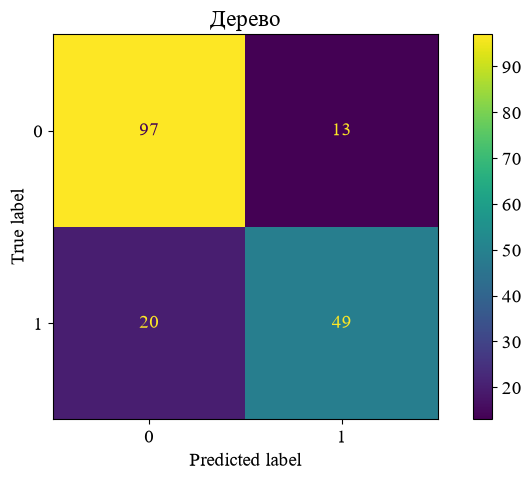

Ліс               precision    recall  f1-score   support

           0       0.82      0.89      0.86       110
           1       0.80      0.70      0.74        69

    accuracy                           0.82       179
   macro avg       0.81      0.79      0.80       179
weighted avg       0.81      0.82      0.81       179



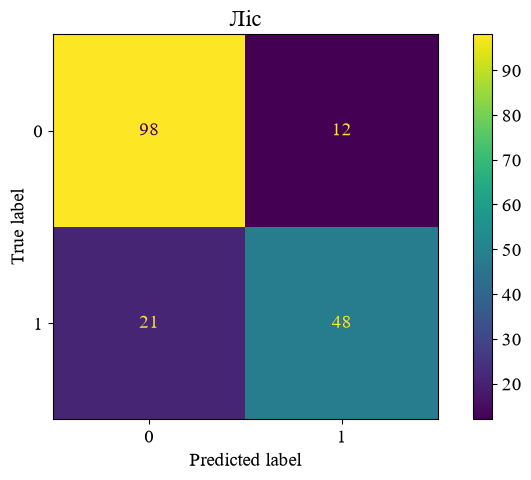

,Модель,CV accuracy,Test accuracy,Параметри
0,Логістична,0.801983,0.793296,{'model__C': 0.1}
1,Дерево,0.814653,0.815642,"{'model__max_depth': 3, 'model__min_samples_le..."
2,Ліс,0.816012,0.815642,"{'model__max_depth': None, 'model__min_samples..."


Найкраща за CV: Ліс


,Справжні,Прогноз
534,0,0
296,0,0
124,0,0
199,0,1
413,0,0
380,1,1
281,0,0
327,1,1
633,0,0
167,0,0


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Справжні,Прогноз
741,1,male,36.0,1,0,78.8500,S,0,0
385,2,male,18.0,0,0,73.5000,S,0,0
536,1,male,45.0,0,0,26.5500,S,0,1
3,1,female,35.0,1,0,53.1000,S,1,1
496,1,female,54.0,1,0,78.2667,C,1,1
773,3,male,NaN,0,0,7.2250,C,0,0
824,3,male,2.0,4,1,39.6875,S,0,0
766,1,male,NaN,0,0,39.6000,C,0,0
485,3,female,NaN,3,1,25.4667,S,0,0
886,2,male,27.0,0,0,13.0000,S,0,0


In [6]:
# Завдання 2. Три класифікатори, оптимальні параметри, метрики та 10 прогнозів. Поділ, три класифікатори та GridSearchCV.
X=df.drop(columns='Survived');y=df.Survived
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=25,stratify=y)
numeric=X.select_dtypes(include='number').columns.tolist()
categorical=X.select_dtypes(exclude='number').columns.tolist()
pre=ColumnTransformer([
    ('num',Pipeline([('fill',SimpleImputer()),('scale',StandardScaler())]),numeric),
    ('cat',Pipeline([('fill',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore'))]),categorical)])
models={'Логістична':LogisticRegression(max_iter=3000),'Дерево':DecisionTreeClassifier(random_state=25),'Ліс':RandomForestClassifier(random_state=25,n_jobs=1)}
grids={'Логістична':{'model__C':[0.1,1,10]},'Дерево':{'model__max_depth':[3,5,None],'model__min_samples_leaf':[1,5]},'Ліс':{'model__n_estimators':[100],'model__max_depth':[5,None],'model__min_samples_leaf':[1,3]}}
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=25)
fitted={}; rows=[]
for name,model in models.items():
    grid=GridSearchCV(Pipeline([('pre',pre),('model',model)]),grids[name],cv=cv,scoring='accuracy',n_jobs=1)
    grid.fit(X_train,y_train);fitted[name]=grid
    pred=grid.predict(X_test)
    rows.append([name,grid.best_score_,accuracy_score(y_test,pred),grid.best_params_])
    print(name,classification_report(y_test,pred,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test,pred);plt.title(name);plt.show()
results=pd.DataFrame(rows,columns=['Модель','CV accuracy','Test accuracy','Параметри']);display(results)
best_name=results.loc[results['CV accuracy'].idxmax(),'Модель'];best=fitted[best_name]
print('Найкраща за CV:',best_name)
display(pd.DataFrame({'Справжні':y_test,'Прогноз':best.predict(X_test)}).head(20))
sample=X_test.sample(10,random_state=25)
display(sample.assign(Справжні=y_test.loc[sample.index],Прогноз=best.predict(sample)))

In [7]:
# Висновок. Завдання 2. Числові пропуски заповнюються середнім, категоріальні — модою тільки за навчальними даними. Побудовано три класифікатори і прогноз для 10 випадкових тестових пасажирів. Результати порівняно за accuracy і класифікаційними звітами.